# 02 · Análisis exploratorio de datos (tarea 2.4)

**Proyecto 1 · Innovación Tecnológica con IA · Grupo 4** — Identificación de especies de aves de Colombia por su canto.

En este notebook exploramos las grabaciones que descargamos de xeno-canto para las 15 especies objetivo: calidad de los datos, distribuciones y exploración acústica. La lógica está en `src/analysis/eda.py`; aquí la ejecutamos y comentamos. Las conclusiones las llevamos a las secciones II y III del [reporte 2](../docs/reporte_entrega_2.md).

> Requiere haber corrido `download`, `depurar` y `preprocess` (ver [`docs/guia_etapa_2.md`](../docs/guia_etapa_2.md)).

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent   # carpeta entrega_2/
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_rows", 60, "display.width", 200, "display.float_format", "{:.3f}".format)
RESULTS, FIGURES, PROCESSED = ROOT / "experiments/results", ROOT / "docs/figuras", ROOT / "data/processed"


In [2]:
from src.analysis import eda
from src.data.preprocess import MFCC_FILE
from src.utils.helpers import load_json

metadata = pd.read_csv("data/metadata/xeno_canto.csv", low_memory=False)
manifest = pd.read_csv("data/metadata/depuracion.csv")
index = pd.read_csv(PROCESSED / "index.csv")
features = np.load(PROCESSED / MFCC_FILE)
audio_config = load_json(PROCESSED / "audio_config.json")
files = eda.downloaded_metadata(metadata, manifest)

print(f"Grabaciones disponibles en xeno-canto (15 especies, Colombia): {len(metadata)}")
print(f"Descargadas (calidad A/B, máx. 60 por especie): {len(manifest)} | conservadas: {manifest['conservar'].sum()}")
print(f"Ventanas de 5 s: {len(index)} | características MFCC por ventana: {features.shape[1]}")

Grabaciones disponibles en xeno-canto (15 especies, Colombia): 2724
Descargadas (calidad A/B, máx. 60 por especie): 870 | conservadas: 822
Ventanas de 5 s: 11159 | características MFCC por ventana: 80


## 1. Selección de especies

Las 15 especies objetivo en el ranking nacional (criterio de 30 grabaciones A/B) y en el rectángulo del Valle del Cauca (presencia regional).

In [3]:
from src.main import read_species_list

targets = read_species_list("data/especies_objetivo.txt")
national = pd.read_csv(RESULTS / "ranking_especies.csv").set_index("especie")
valle = pd.read_csv(RESULTS / "ranking_especies_valle.csv").set_index("especie")
selection = national.loc[targets, ["nombre_en", "grabaciones", "grabadores", "minutos"]].join(
    valle["grabaciones"].rename("grabaciones_valle"))
print(f"Especies con ≥ 30 grabaciones A/B en Colombia: {int(national['cumple'].sum())} de {len(national)}")
selection.sort_values("grabaciones", ascending=False)

Especies con ≥ 30 grabaciones A/B en Colombia: 267 de 1552


,nombre_en,grabaciones,grabadores,minutos,grabaciones_valle
especie,,,,,
Henicorhina leucophrys,Grey-breasted Wood Wren,393,84,303.500,5
Troglodytes aedon,House Wren,214,86,142.800,10
Zonotrichia capensis,Rufous-collared Sparrow,159,68,115.500,6
Pheugopedius mystacalis,Whiskered Wren,153,64,132.300,5
Myadestes ralloides,Andean Solitaire,144,64,155.500,6
Synallaxis azarae,Azara's Spinetail,130,59,110.200,3
Rupornis magnirostris,Roadside Hawk,123,59,108.400,7
Henicorhina leucosticta,White-breasted Wood Wren,122,37,104.500,3
Ortalis columbiana,Colombian Chachalaca,100,51,112.800,7


## 2. Depuración (tarea 2.3)

El manifiesto marca qué archivos conservamos y por qué descartamos los demás; no borramos ningún archivo.

In [4]:
from src.data.clean import summarize_manifest

summary_clean = summarize_manifest(manifest)
display(summary_clean)
print(summary_clean.drop(columns="especie").sum().to_string())

,especie,descargadas,ilegible,duplicado,muy_corto,fondo_objetivo,conservadas,minutos_conservados,posible_voz
0,Cyphorhinus_thoracicus,60,0,0,0,3,57,66.800,1
1,Henicorhina_leucophrys,60,0,0,0,1,59,39.400,1
2,Henicorhina_leucosticta,60,0,0,0,2,58,43.400,0
3,Myadestes_ralloides,60,0,1,0,5,54,45.900,0
4,Odontophorus_hyperythrus,51,0,0,0,2,49,36.600,0
5,Ortalis_columbiana,60,0,0,0,5,55,64.300,0
6,Pheugopedius_mystacalis,60,0,0,0,6,54,48.600,0
7,Rupornis_magnirostris,60,0,0,0,2,58,54.800,0
8,Scytalopus_alvarezlopezi,48,0,0,0,0,48,35.200,1
9,Scytalopus_vicinior,51,0,0,0,0,51,47.800,0


descargadas           870.000
ilegible                0.000
duplicado               2.000
muy_corto               2.000
fondo_objetivo         44.000
conservadas           822.000
minutos_conservados   664.600
posible_voz             4.000


## 3. Calidad de los datos

### 3.1 Valores faltantes en los metadatos

In [5]:
eda.missing_values(metadata)

,campo,faltantes,porcentaje
0,sex,2634,96.700
1,stage,2520,92.500
2,rmk,1318,48.400
3,time,512,18.800
4,type,348,12.800
5,alt,161,5.900
6,date,158,5.800
7,lon,145,5.300
8,lat,145,5.300
9,q,25,0.900


### 3.2 Calidad asignada por la comunidad (A–E)

Solo descargamos A y B; la figura muestra todo lo disponible para dimensionar cuánto dejamos por fuera.

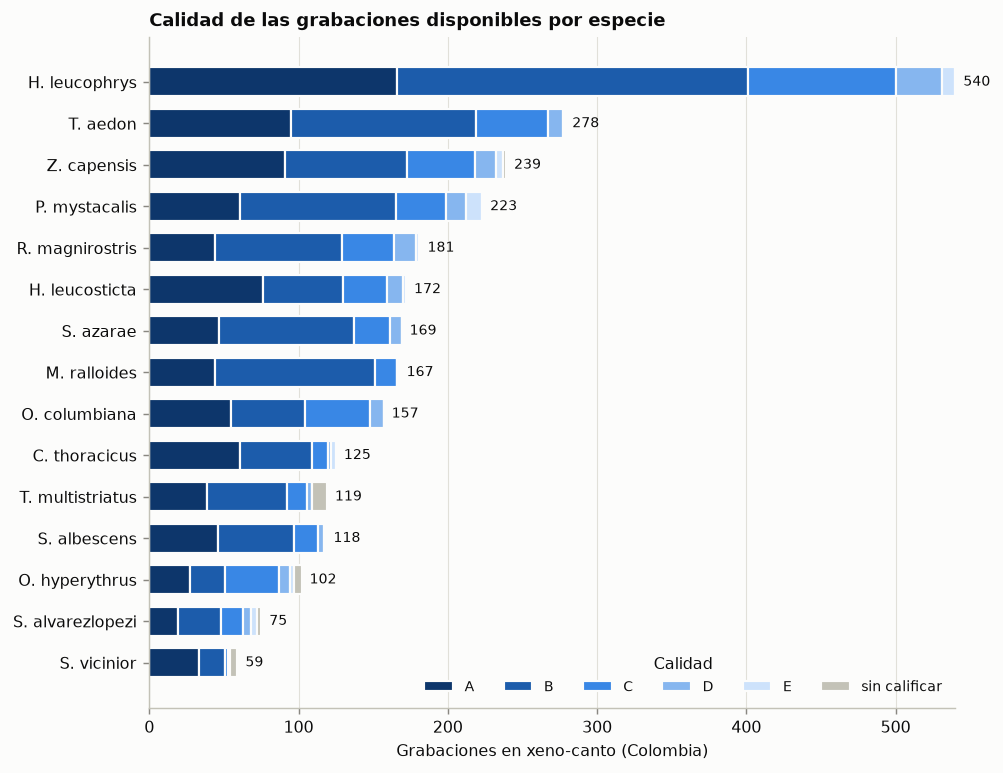

Proporción por calidad (%):
q
A               33.200
B               42.300
C               17.100
D                4.900
E                1.500
sin calificar    0.900


In [6]:
display(Image(eda.plot_quality(metadata, FIGURES / "eda_calidad.png")))
quality = eda.quality_table(metadata)
print("Proporción por calidad (%):")
print((100 * quality.drop(columns=["especie", "total"]).sum() / quality["total"].sum()).round(1).to_string())

### 3.3 Duración, frecuencia de muestreo y etiquetas débiles

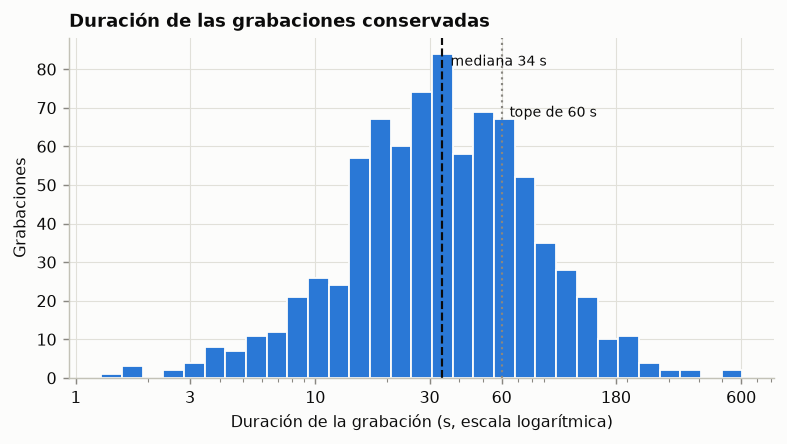

count   822.000
mean     48.500
std      52.900
min       1.300
10%      10.400
25%      18.400
50%      34.000
75%      60.500
90%      98.200
max     607.000

Frecuencia de muestreo de los archivos (Hz):
frecuencia_muestreo
44100     535
48000     264
96000       8
32000       6
192000      5
16000       2
22050       1
24000       1

Grabaciones con otras especies de fondo (etiquetas débiles): 13.4 %


In [7]:
display(Image(eda.plot_durations(files, FIGURES / "eda_duraciones.png", audio_config.get("max_seconds"))))
print(files["duracion_s"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_string())
print("\nFrecuencia de muestreo de los archivos (Hz):")
print(files["frecuencia_muestreo"].value_counts().to_string())
also = files["also"].map(lambda v: len(eda.parse_also(v)) > 0)
print(f"\nGrabaciones con otras especies de fondo (etiquetas débiles): {100 * also.mean():.1f} %")

## 4. Distribuciones

### 4.1 Resumen por especie y desbalance

,especie,grabaciones,calidad_A,calidad_B,minutos,duracion_mediana_s,grabadores,max_por_grabador_pct,con_otras_especies_pct,cantos_pct,ventanas
0,Henicorhina_leucophrys,59,59,0,39.400,24.100,29,10.200,5.100,76.300,708
1,Henicorhina_leucosticta,58,58,0,43.400,36.200,17,20.700,24.100,82.800,810
2,Rupornis_magnirostris,58,42,16,54.800,38.700,37,8.600,15.500,37.900,832
3,Troglodytes_aedon,58,58,0,32.100,25.900,28,19.000,22.400,70.700,663
4,Zonotrichia_capensis,57,57,0,34.700,31.300,32,10.500,17.500,78.900,704
5,Synallaxis_albescens,57,45,12,36.100,29.900,36,7.000,12.300,75.400,723
6,Cyphorhinus_thoracicus,57,57,0,66.800,47.200,26,29.800,7.000,91.200,928
7,Ortalis_columbiana,55,53,2,64.300,49.700,35,9.100,14.500,56.400,865
8,Synallaxis_azarae,54,44,10,37.600,31.000,35,5.600,14.800,70.400,692
9,Myadestes_ralloides,54,40,14,45.900,33.900,39,7.400,13.000,79.600,789


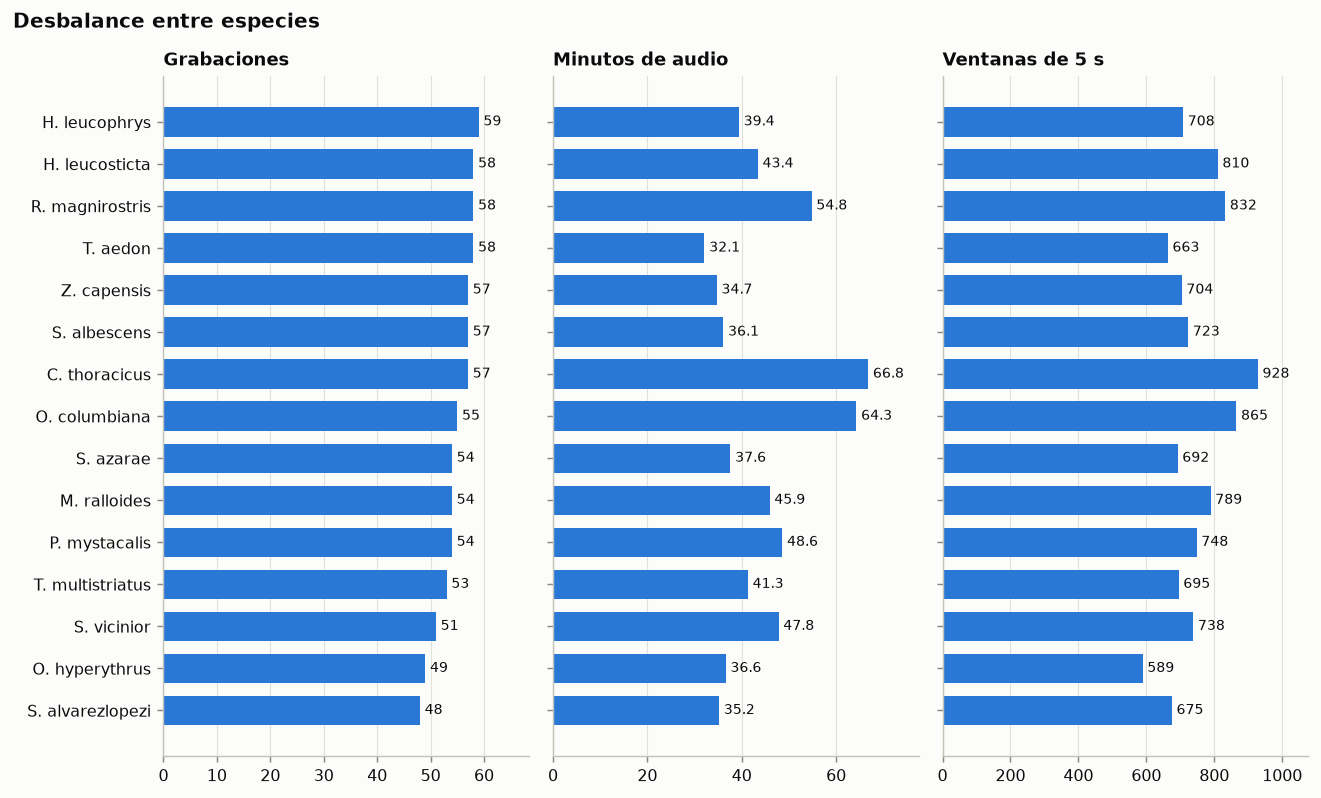

Razón máx/mín de grabaciones: 1.2
Razón máx/mín de minutos: 2.1
Razón máx/mín de ventanas: 1.6


In [8]:
summary = eda.species_summary(files, index)
display(summary)
display(Image(eda.plot_balance(summary, FIGURES / "eda_desbalance.png")))
for column in ("grabaciones", "minutos", "ventanas"):
    print(f"Razón máx/mín de {column}: {summary[column].max() / summary[column].min():.1f}")

### 4.2 Grabadores por especie

Si una sola persona aporta buena parte de las grabaciones de una especie, el modelo puede aprender su equipo o su sitio en lugar del canto.

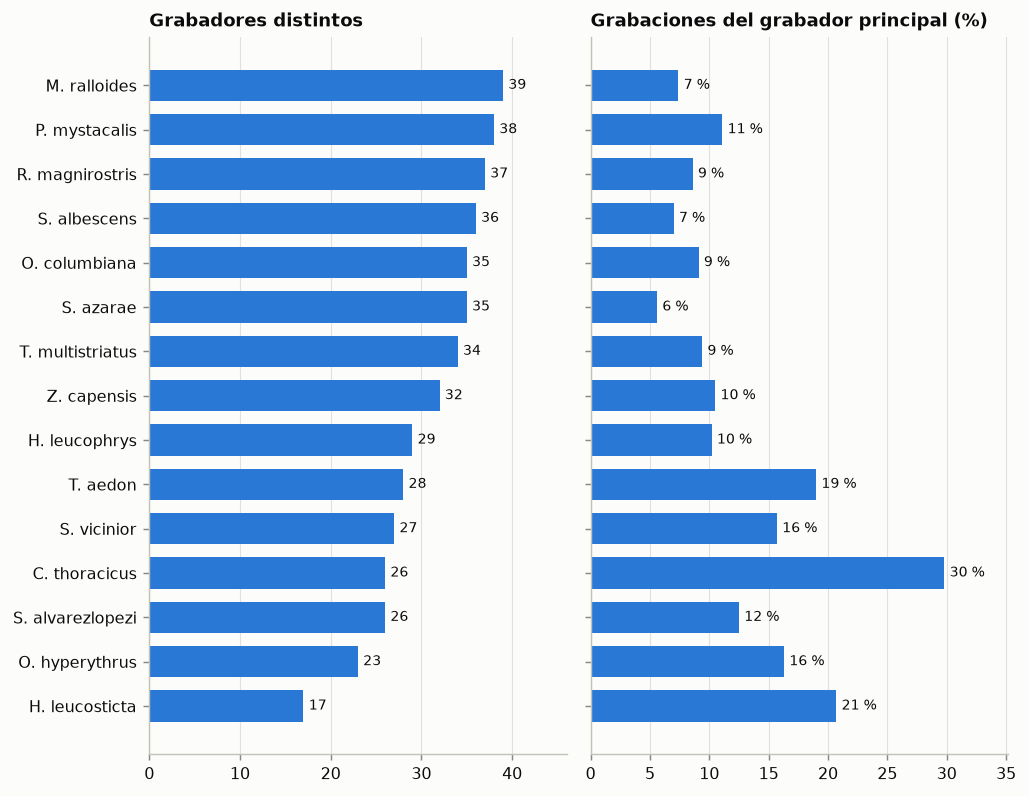

In [9]:
display(Image(eda.plot_recorders(summary, FIGURES / "eda_grabadores.png")))

### 4.3 Tipo de vocalización

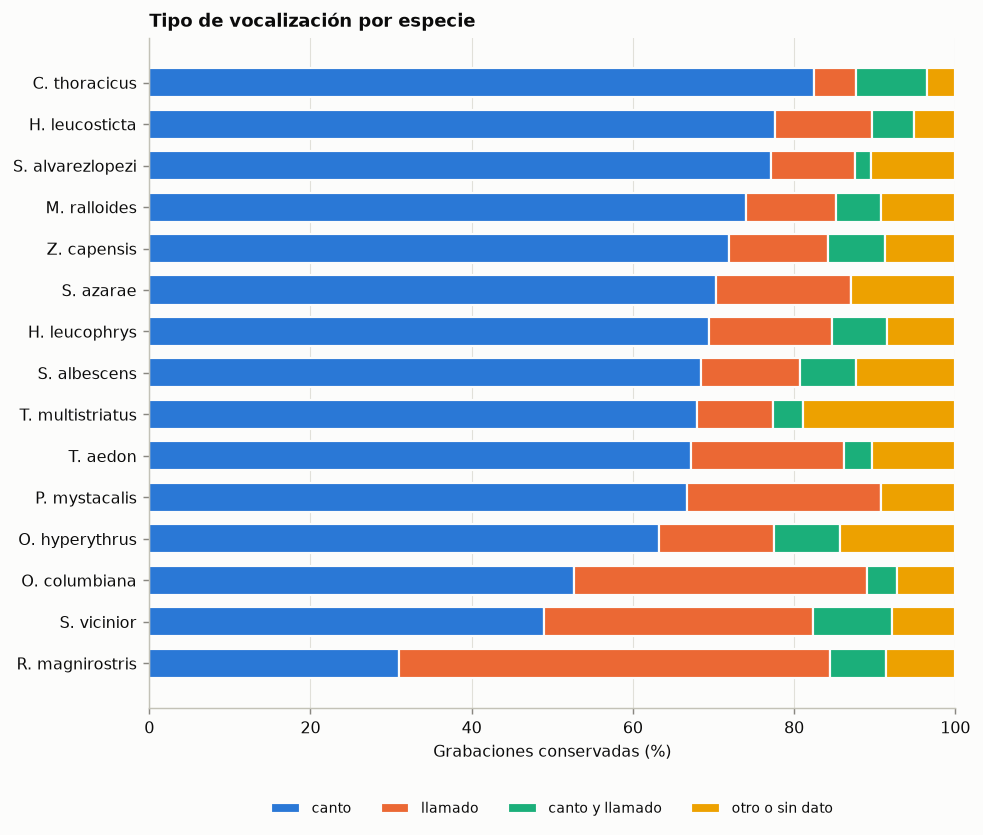

In [10]:
display(Image(eda.plot_vocalization_types(files, FIGURES / "eda_tipos_vocalizacion.png")))

### 4.4 Distribución geográfica y licencias

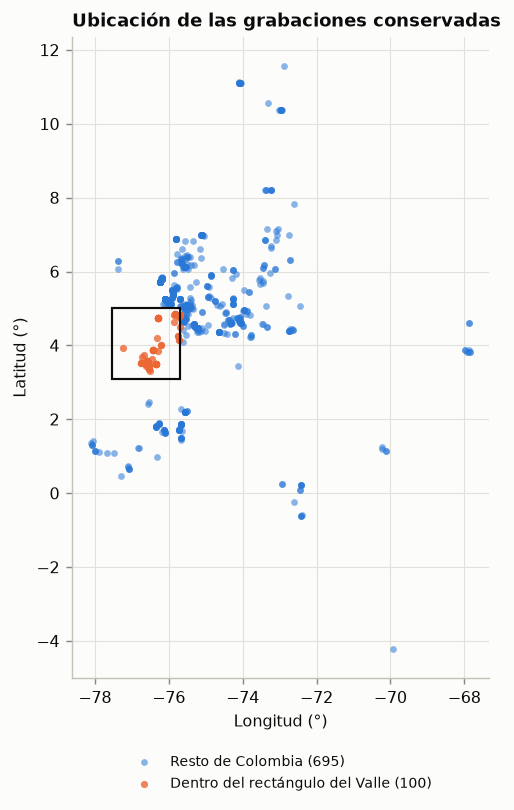

,licencia,grabaciones,porcentaje
0,CC BY-NC-SA 4.0,520,63.300
1,CC BY-NC-SA 3.0,119,14.500
2,CC BY-NC-ND 4.0,104,12.700
3,CC BY-NC-ND 2.5,63,7.700
4,CC BY 4.0,9,1.100
5,CC BY-NC-ND 3.0,5,0.600
6,CC BY-SA 4.0,2,0.200


In [11]:
display(Image(eda.plot_map(files, FIGURES / "eda_mapa.png")))
display(eda.license_table(files))

## 5. Exploración acústica

### 5.1 Espectrogramas representativos

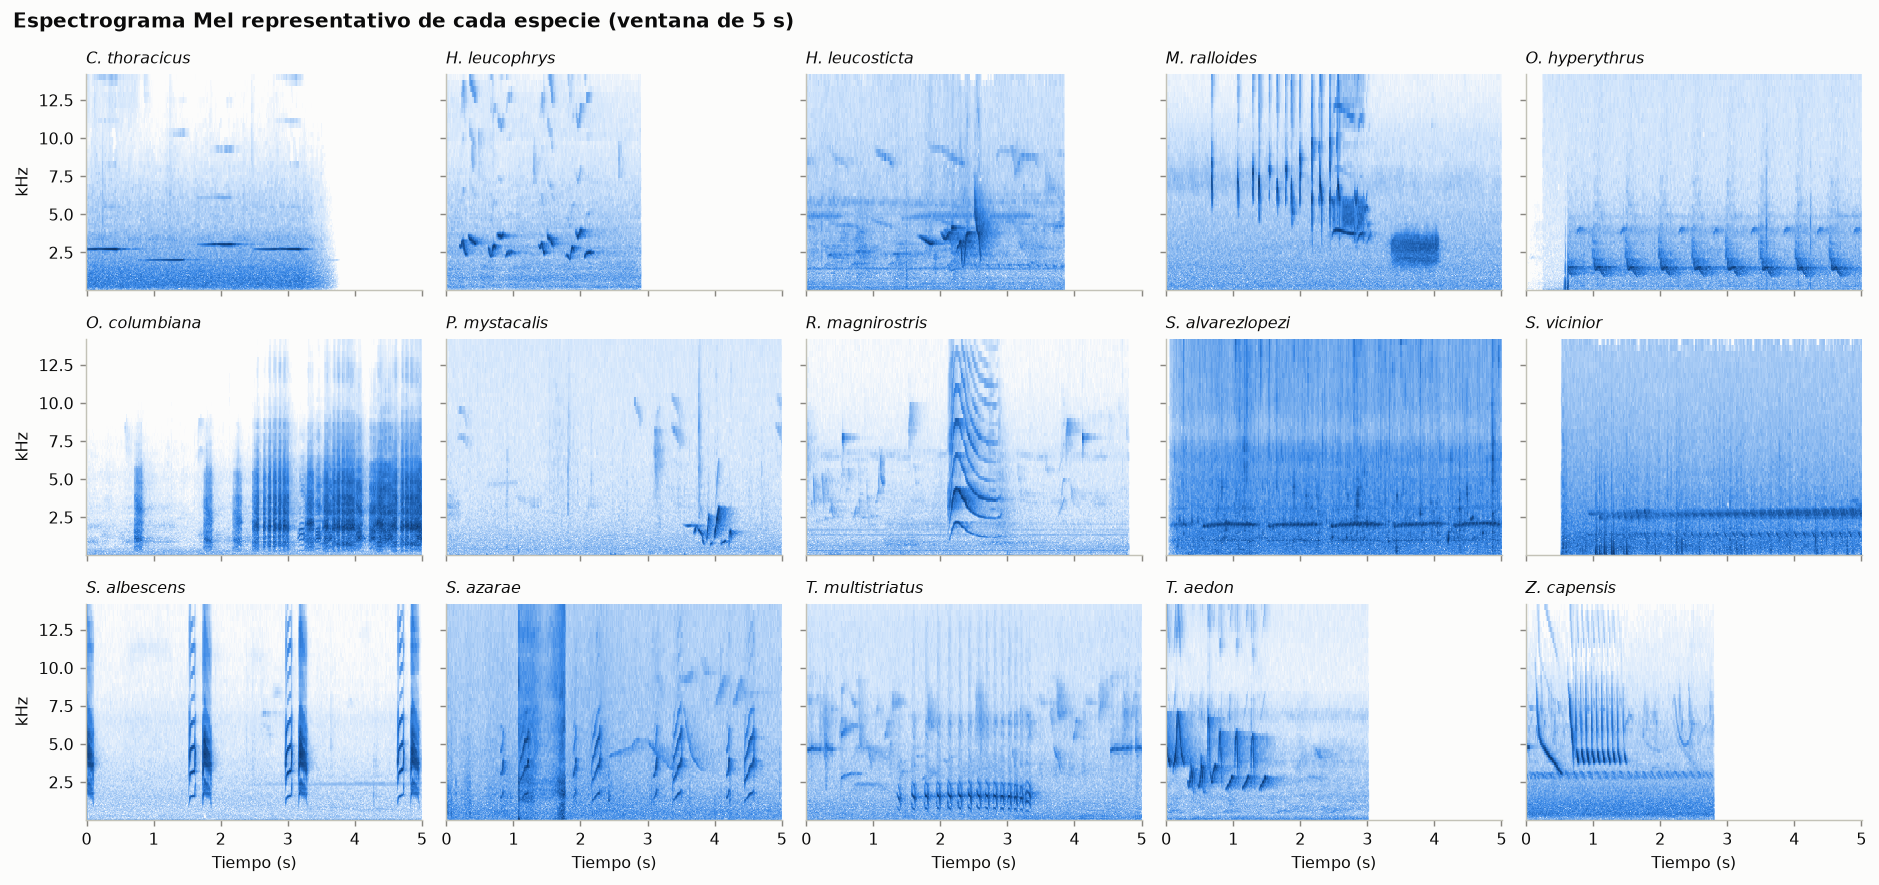

In [12]:
profiles = eda.band_profiles(index, PROCESSED)
frequencies = eda.mel_frequencies(audio_config)
display(Image(eda.plot_example_spectrograms(index, PROCESSED, audio_config, FIGURES / "eda_espectrogramas.png", profiles)))

### 5.2 Perfil espectral medio y bandas dominantes

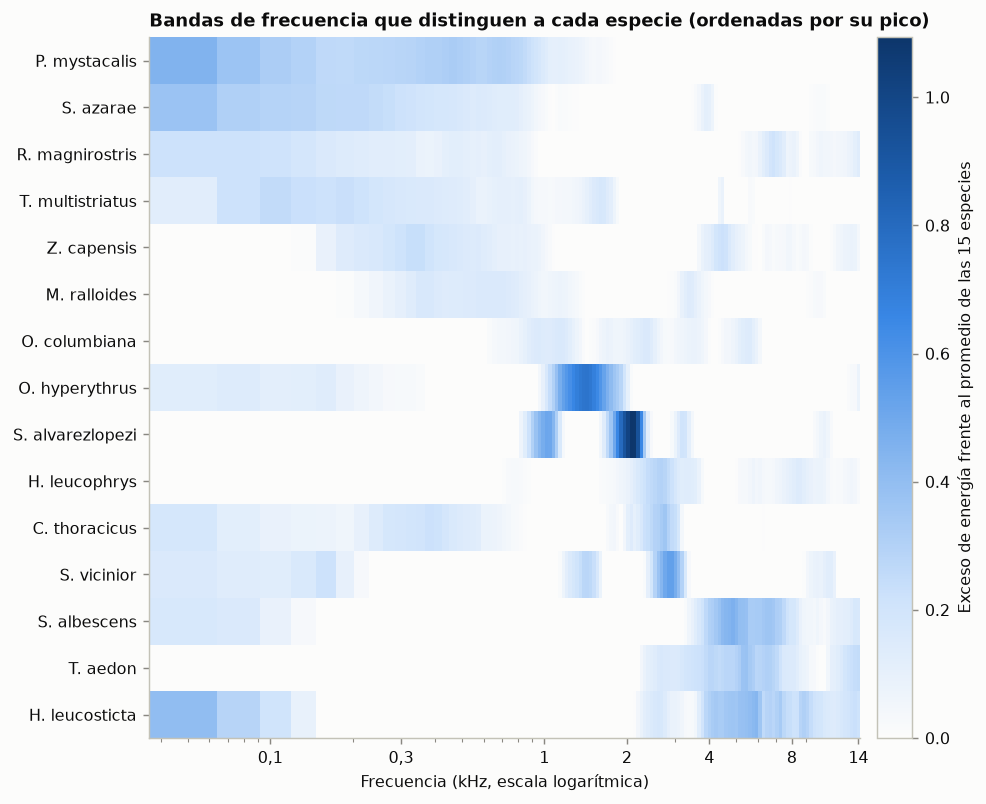

,especie,pico_khz,banda_min_khz,banda_max_khz
0,Pheugopedius_mystacalis,0.050,0.050,0.880
1,Synallaxis_azarae,0.050,0.050,0.380
2,Rupornis_magnirostris,0.080,0.050,0.300
3,Thamnophilus_multistriatus,0.110,0.050,0.490
4,Zonotrichia_capensis,0.350,0.190,0.600
5,Myadestes_ralloides,0.380,0.300,0.910
6,Ortalis_columbiana,1.140,0.850,1.240
7,Odontophorus_hyperythrus,1.430,1.110,1.750
8,Scytalopus_alvarezlopezi,2.070,1.850,2.260
9,Henicorhina_leucophrys,2.680,2.200,3.010


In [13]:
by_species = eda.species_profiles(profiles, index)
display(Image(eda.plot_species_profiles(by_species, frequencies, FIGURES / "eda_perfil_espectral.png")))
eda.dominant_bands(by_species, frequencies)

### 5.3 Especies parecidas

Distancia entre los centroides de cada especie en el espacio de estadísticas de MFCC (estandarizado). Los pares más cercanos son los candidatos a confundirse.

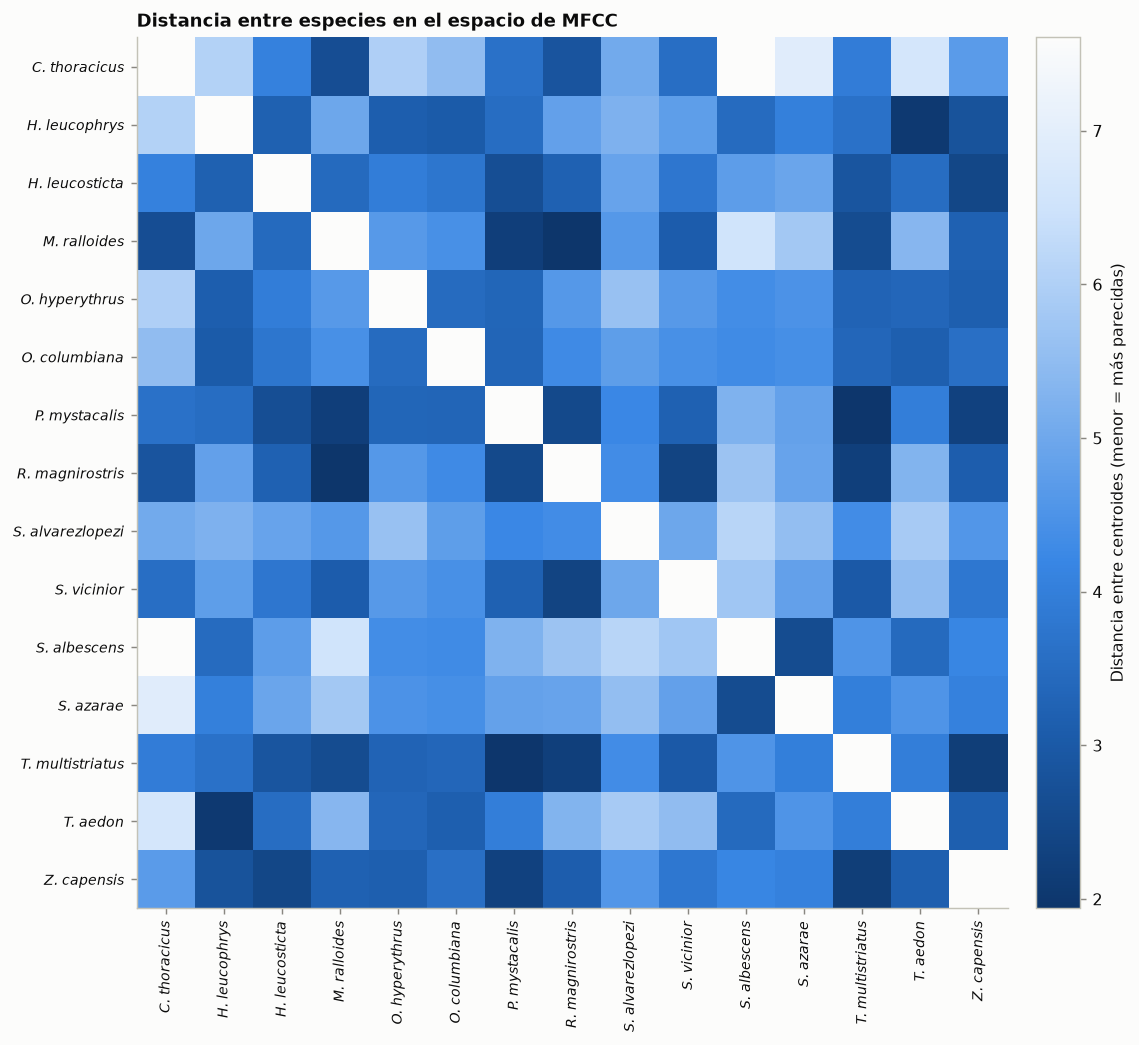

,especie_1,especie_2,distancia
0,Myadestes_ralloides,Rupornis_magnirostris,1.940
1,Pheugopedius_mystacalis,Thamnophilus_multistriatus,1.970
2,Henicorhina_leucophrys,Troglodytes_aedon,2.070
3,Thamnophilus_multistriatus,Zonotrichia_capensis,2.190
4,Myadestes_ralloides,Pheugopedius_mystacalis,2.220
5,Rupornis_magnirostris,Thamnophilus_multistriatus,2.250
6,Pheugopedius_mystacalis,Zonotrichia_capensis,2.310
7,Rupornis_magnirostris,Scytalopus_vicinior,2.370


In [14]:
distances = eda.species_distances(features, index)
display(Image(eda.plot_species_distances(distances, FIGURES / "eda_distancias_especies.png")))
eda.closest_pairs(distances)

### 5.4 Agrupamiento no supervisado (k-means)

¿Las ventanas se separan por especie sin usar las etiquetas? Aplicamos k-means con k = 15 sobre las estadísticas de MFCC y comparamos los grupos con las especies.

{
  "k": 15,
  "n_ventanas": 11159,
  "pureza": 0.25566807061564656,
  "pureza_azar_clase_mayoritaria": 0.08316157361770768,
  "ari": 0.07120927976544804,
  "nmi": 0.18579942792303009
}


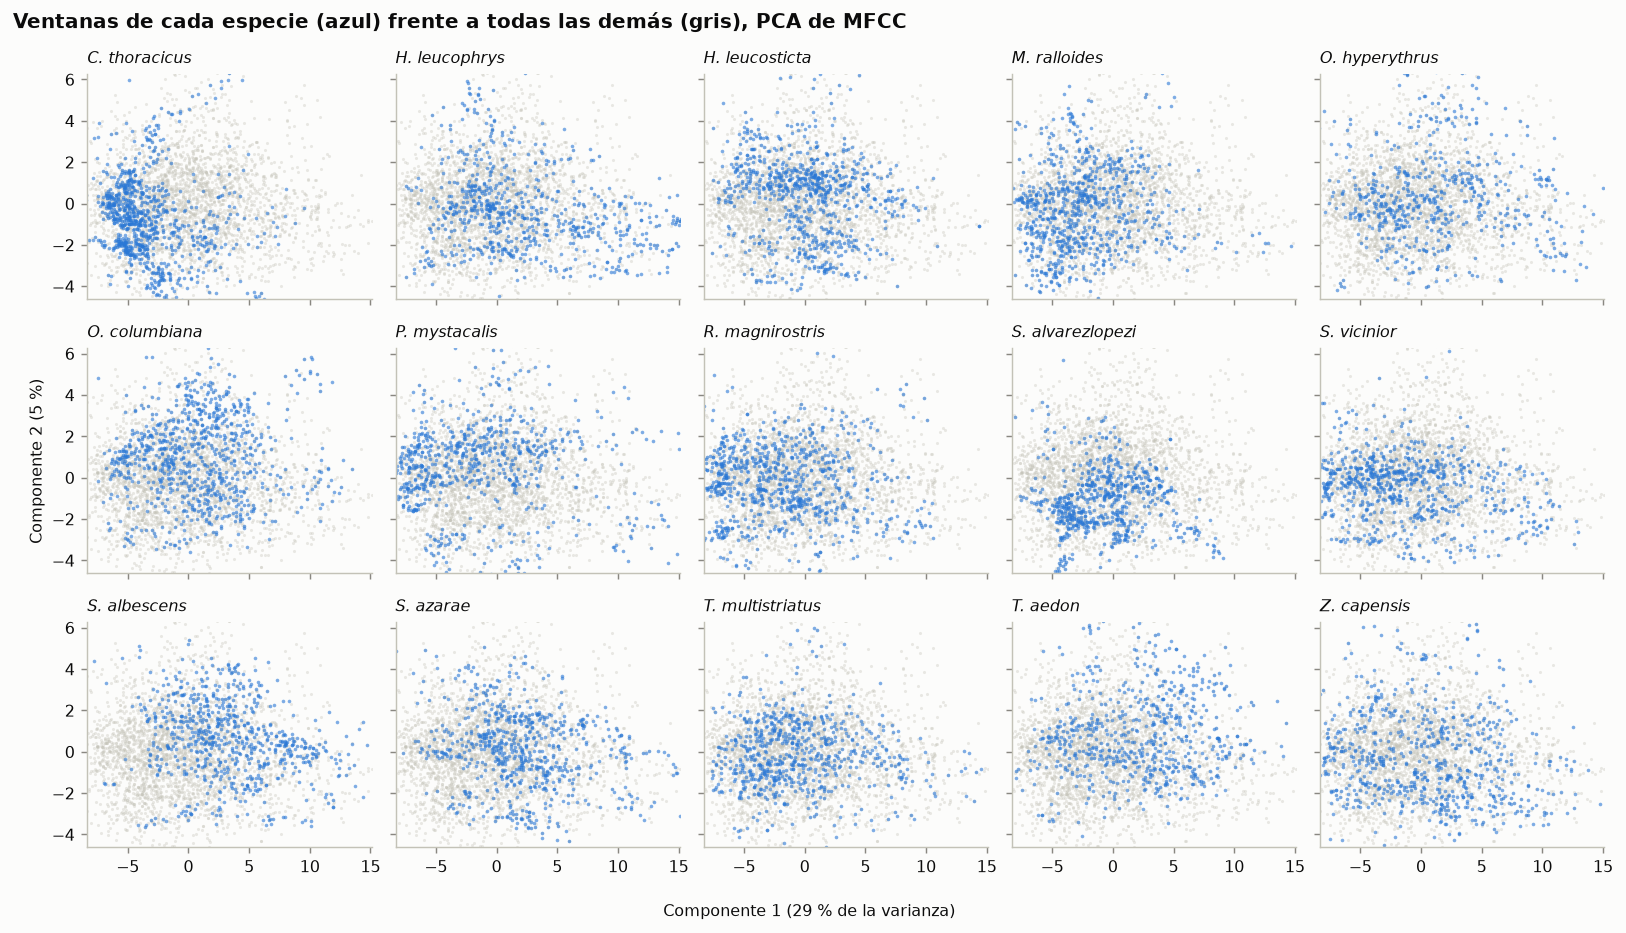

In [15]:
measures, contingency = eda.kmeans_exploration(features, index)
print(json.dumps(measures, indent=2))
display(Image(eda.plot_pca_small_multiples(features, index, FIGURES / "eda_pca_especies.png")))

## 6. Conclusiones del análisis exploratorio

1. **Los datos son suficientes y están razonablemente balanceados.** Conservamos 822 grabaciones (665 minutos) de 178 grabadores; cada especie tiene entre 48 y 59 grabaciones y entre 589 y 928 ventanas (razón máxima/mínima de 1,6). El desbalance es moderado, así que la exactitud balanceada y el F1 macro son las métricas adecuadas y los pesos por clase bastan para compensarlo.
2. **Los metadatos esenciales están completos.** Especie, grabador, licencia, duración y frecuencia de muestreo no tienen faltantes; sexo (97 %) y etapa de vida (93 %) casi nunca se registran, por lo que no los usamos. El 5 % sin coordenadas solo afecta el mapa.
3. **La duración es muy variable** (mediana 34 s, de 1,3 s a 10 min). El 25 % de las grabaciones supera los 60 s; con el tope de 60 s por grabación dejamos por fuera el 27 % de los minutos, pero evitamos que unas pocas grabaciones largas dominen su especie.
4. **Las etiquetas son débiles.** El 13 % de las grabaciones conservadas declara otras especies al fondo y la etiqueta aplica a toda la grabación, no a cada ventana: hay ventanas con silencio, ruido u otras aves. Además, entre el 9 % y el 62 % de las grabaciones de cada especie no contienen cantos (son llamados u otros sonidos); *Rupornis magnirostris*, *Ortalis columbiana* y *Scytalopus vicinior* son las más heterogéneas.
5. **El ruido de baja frecuencia es importante.** En seis especies la banda que más las distingue queda por debajo de 1 kHz, donde no cantan: es ruido de fondo de los sitios de grabación. Es un atajo que el modelo podría aprender, y un argumento para evaluar un filtro pasa-altos o subir la frecuencia mínima en la Etapa 3.
6. **Las especies no se separan solas.** K-means sobre las estadísticas de MFCC logra una pureza de 0,26 (frente a 0,08 del azar) y un ARI de 0,07: hay señal, pero un resumen global de la ventana no basta, lo que justifica modelos supervisados que usen la estructura tiempo-frecuencia del espectrograma.
7. **Pares por vigilar:** *H. leucophrys* – *T. aedon*, *M. ralloides* – *R. magnirostris* y *P. mystacalis* – *T. multistriatus* son los más cercanos en el espacio de MFCC.
